In [1]:
from tensorflow import keras
import tensorflow as tf
from tensorflow.keras import layers,callbacks
import pandas as pd
from tensorflow.keras.utils import plot_model
#for scaling the data set but this is tf only or was tf only
from sklearn.preprocessing import MinMaxScaler
#MinMaxScaler().fit_transform(df)
from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import EarlyStopping


red_wine=pd.read_csv('c:/Users/andee/Downloads/red-wine.csv')
ion=pd.read_csv('c:/Users/andee/Downloads/ion.csv')

In [11]:
df = ion.copy()
df['Class'] = df['Class'].map({'good': 0, 'bad': 1})

df_train = df.sample(frac=0.7, random_state=0)
df_valid = df.drop(df_train.index)

max_ = df_train.max(axis=0)
min_ = df_train.min(axis=0)

df_train = (df_train - min_) / (max_ - min_)
df_valid = (df_valid - min_) / (max_ - min_)
df_train.dropna(axis=1, inplace=True) # drop the empty feature in column 2
df_valid.dropna(axis=1, inplace=True)

X_train = df_train.drop('Class', axis=1)
X_valid = df_valid.drop('Class', axis=1)
y_train = df_train['Class']
y_valid = df_valid['Class']

X_train.shape

(246, 34)

In [ ]:
#create training and validation splits
df_train = red_wine.sample(frac=0.7, random_state=0)
df_valid = red_wine.drop(df_train.index)
display(df_train.head(4))

#scale to [0,1]
max_=df_train.max(axis=0)
min_=df_train.min(axis=0)
df_train= (df_train-min_)/(max_ - min_)
df_valid=(df_valid-min_)/(max_-min_)

#split features and target
X_train=df_train.drop('quality',axis=1)
X_valid = df_valid.drop('quality', axis=1)
y_train = df_train['quality']
y_valid = df_valid['quality']

In [ ]:
print(X_train.shape)

In [ ]:
model = keras.Sequential([layers.Dense(units=1, input_shape=[3])])

In [ ]:
print("GPUs:", tf.config.list_physical_devices('GPU'))

In [ ]:
early_stopping = callbacks.EarlyStopping(
    min_delta=0.001, #minimum amount of change to count as an improvement
    patience=20, #how many epochs to wait before stopping
    restore_best_weights=True
)
model1 = keras.Sequential([
    # the hidden ReLU layers
    layers.Dense(1024, activation='relu', input_shape=[11]),
    layers.Dropout(rate=0.3), #applies 30% dropout to the next layer
    layers.BatchNormalization(),#faster training 
    layers.Dense(1024, activation='relu'),
    layers.Dropout(rate=0.3),
    layers.BatchNormalization(),
    layers.Dense(1024, activation='relu'),
    layers.Dropout(rate=0.3),
    layers.BatchNormalization(),
    # the linear output layer 
    layers.Dense(1)
])
model1.summary()


In [13]:
model2 = keras.Sequential([
    layers.Dense(4, activation='relu', input_shape=[34]),
    layers.Dense(4, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

c:\Users\andee\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [15]:
model2.compile(
    optimizer='adam',
    loss = 'binary_crossentropy',
    metrics=['binary_accuracy']
)

In [ ]:
print(X_train.shape)

(246, 34)


In [16]:
early_stopping1 = keras.callbacks.EarlyStopping(
    patience=10,
    min_delta=0.001,
    restore_best_weights=True
)

history2 = model2.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=512,
    epochs=1000,
    callbacks=[early_stopping1],
    verbose=0, # hide the output because we have so many epochs
)

Best Validation Loss: 0.2534
Best Validation Accuracy: 0.8762


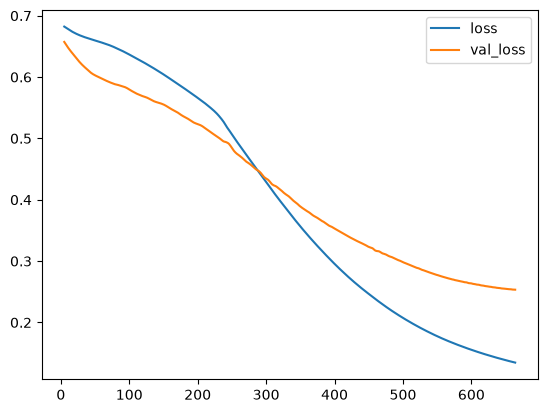

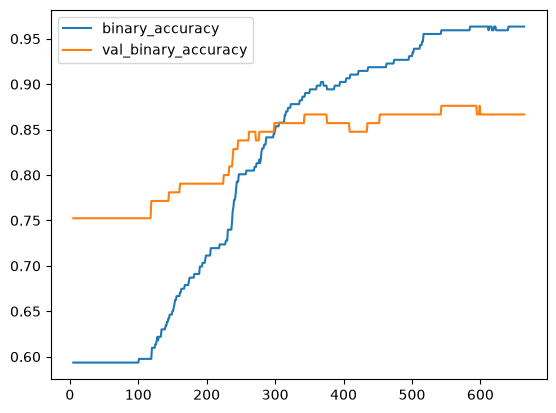

: 

In [ ]:
history_df1 = pd.DataFrame(history2.history)
history_df1.loc[5:, ['loss', 'val_loss']].plot()
history_df1.loc[5:,['binary_accuracy', 'val_binary_accuracy']].plot()

print(("Best Validation Loss: {:0.4f}" +\
      "\nBest Validation Accuracy: {:0.4f}")\
      .format(history_df1['val_loss'].min(), 
              history_df1['val_binary_accuracy'].max()))

In [ ]:
model1.get_weights()

In [ ]:
plot_model(model1,
           show_shapes =True,
           show_layer_names=True,
           to_file="network.png")

In [ ]:
model1.compile(
    optimizer="adam",
    loss="mae"
)

In [ ]:
#pip install tensorflow-directml-plugin
history = model1.fit(
    X_train,y_train,
    validation_data=(X_valid, y_valid),
    batch_size=256,
    epochs=100,
    callbacks=[early_stopping],
    verbose=0 #turns off trainning log
    
    )

In [ ]:
history_df = pd.DataFrame(history.history)

history_df[['loss','val_loss']].plot()